# Baseline Approach

The overall goal of this notebook is to establish a baseline benchmark for evaluating the future models that proposed. Since the goal is to estimate a value that doesn't have a comparable benchmark (which is somewhat moot since statistically significant returns factor is more important), it is necessary to have some sort of framework to measure against.

There are two goals for analyzing the performance of a model which are

1. Fundamental data prediction: how does the performance of a proposed model compare against using lagged differences.
2. Statistically significant factor of returns: is the factor statistically significant and does that factor contain (more or better) meaningful information than Bloomberg Estimated.

For simplicity this model will use the last observation of the quarter for prediction, and the analysis is restricted only to financial variables that are subject to a lag. Variables that combine accounting information with contemporaneously observed market data are excluded such as P/E ratio. The results will also be using only SPX, Russell, and NASDAQ for now. 

In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm

import matplotlib.pyplot as plt
from   matplotlib.ticker import FuncFormatter

In [2]:
from tqdm import tqdm
tqdm.pandas()

In [3]:
note_path  = os.getcwd()
repo_path  = os.path.abspath(os.path.join(note_path, ".."))
src_path   = os.path.join(repo_path, "src")
data_path  = os.path.join(repo_path, "data")
db_path    = os.path.join(data_path, "DataBase")
daily_path = os.path.join(db_path, "DailyData")
quart_path = os.path.join(db_path, "Quarterlyized")
base_path  = os.path.join(data_path, "Models", "BaselineModels")

In [4]:
import sys
sys.path.append(src_path)
from OLSModels import OLSModels

In [5]:
add_dict = {
    "lag_vol_rtn": "Lagged",
    "rtn"        : "No",
    "vol_rtn"    : "Contemporaneous"}

In [13]:
ticker_path = os.path.join(data_path, "EquityForecastTickerGuide.xlsx")
df_renamer  = pd.read_excel(io = ticker_path, sheet_name = "Renamer")

raw_renamer = (df_renamer
    .set_index("old_name")
    .loc[lambda x: x.group == "renamer"]
    .new_name
    .to_dict())

RENAMER = {**add_dict, **raw_renamer}

PLOT_RENAMER = (df_renamer
    .set_index("old_name")
    .loc[lambda x: x.group == "plot_renamer"]
    .assign(name = lambda x: x.new_name.str.replace(r"\\n", "\n", regex = True))
    .name
    .to_dict())

FLOAT_FORMAT = "{:.2f}".format

In [7]:
sample_tickers = ['SPX Index', 'RTY Index', 'NDX Index']
stat_method    = ["last"]

# 1. Assessing the predict

We will attempt to predict the future change in fundamental data. We expect the quality of our model to be quite weak but our analysis is more about comparison than in asbolute terms therefore we have to set a baseline.

In [8]:
path = os.path.join(base_path, "PredictiveModels.pkl")
with open(path, "rb") as f: models = pickle.load(f)
df_params = OLSModels().get_model_params(models)

In [9]:
df_param_prep = (df_params
    .loc[lambda x: x.param_name != "const"]
    .assign(
        ticker     = lambda x: x.name.str.split("-").str[0],
        param_name = lambda x: x.param_name.str.replace("lag_", "").str.replace(RENAMER)))

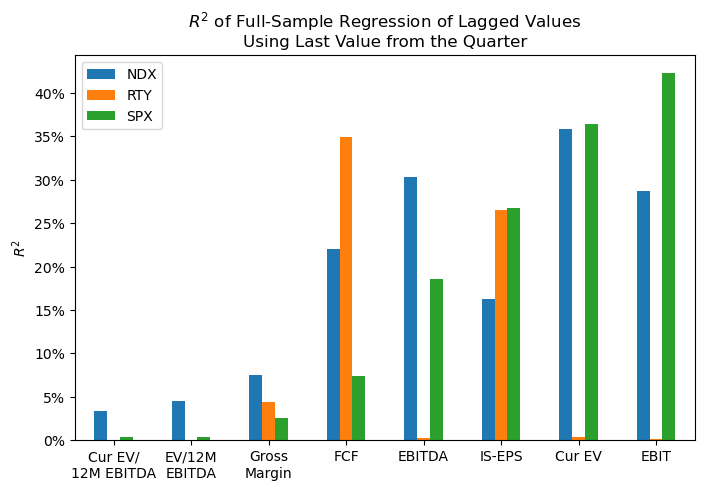

In [16]:
_, axes = plt.subplots(figsize = (8,5))

df_r2_plot = (df_param_prep
    .assign(param_name = lambda x: x.param_name.str.replace(PLOT_RENAMER))
    .rename(columns = {"ticker": ""})
    .pivot(index = "param_name", columns = "", values = "r2")
    .sort_values("SPX"))

(df_r2_plot
    .plot(
        ax     = axes,
        kind   = "bar",
        xlabel = "",
        rot    = 0,
        ylabel = r"$R^2$",
        title  = r"$R^2$ of Full-Sample Regression of Lagged Values" + "\nUsing Last Value from the Quarter"))

axes.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))

In [30]:
display(df_param_prep
    .drop(columns = ["r2", "name"])
    .melt(id_vars = ["param_name", "ticker"])
    .rename(columns = {
        "ticker"    : "Benchmark",
        "param_name": "Parameter",
        "variable"  : ""})
    .pivot(index = ["Benchmark", "Parameter"], columns = "", values = "value")
    .assign(stat_sig = lambda x: np.where(
        (x.pvalue < 0.05) & (np.abs(x.tvalue) > 1.2),
        "Stat. Sig.",
        "Not Stat. Sig."))
    .rename(columns = {
        "param_val": "Coef",
        "pvalue"   : r"$p$-value",
        "tvalue"   : r"$t$-value",
        "stat_sig" : "Stat. Sig"}))

Coef     $p$-value  $t$-value       Stat. Sig
Benchmark Parameter                                                           
NDX       Cur EV             0.660356  4.790674e-11   7.397016      Stat. Sig.
          Cur EV/12M EBITDA  0.195825  7.035777e-02   1.829549  Not Stat. Sig.
          EBIT               0.573382  9.263472e-09   6.281064      Stat. Sig.
          EBITDA             0.551205  2.831698e-09   6.537647      Stat. Sig.
          EV/12M EBITDA      0.219265  3.513833e-02   2.136387      Stat. Sig.
          FCF                0.477604  8.738715e-07   5.252554      Stat. Sig.
          Gross Margin       0.232818  5.984972e-03   2.809827      Stat. Sig.
          IS-EPS             0.459456  3.166731e-05   4.363832      Stat. Sig.
RTY       Cur EV             0.062829  4.904699e-01   0.691670  Not Stat. Sig.
          Cur EV/12M EBITDA  0.001474  9.356123e-01   0.080960  Not Stat. Sig.
          EBIT               0.040360  6.627880e-01   0.437178  Not Stat. Sig.
          EBITDA             0.053355  5.641331e-01   0.578359  Not Stat. Sig.
          EV/12M EBITDA      0.003832  8.425959e-01   0.199016  Not Stat. Sig.
          FCF                0.005420  8.092277e-13   8.016544      Stat. Sig.
          Gross Margin       0.180553  2.587225e-02   2.258173      Stat. Sig.
          IS-EPS             0.002707  1.140642e-09   6.601253      Stat. Sig.
SPX       Cur EV             0.629435  1.428890e-15   8.994992      Stat. Sig.
          Cur EV/12M EBITDA  0.055927  5.123678e-01   0.656855  Not Stat. Sig.
          EBIT               0.660674  3.638299e-18  10.048073      Stat. Sig.
          EBITDA             0.431214  1.068962e-07   5.609526      Stat. Sig.
          EV/12M EBITDA      0.057291  5.016765e-01   0.673625  Not Stat. Sig.
          FCF                0.296012  1.433601e-03   3.255982      Stat. Sig.
          Gross Margin       0.294378  5.993230e-02   1.896888  Not Stat. Sig.
          IS-EPS             0.608231  6.428840e-11   7.087280      Stat. Sig.

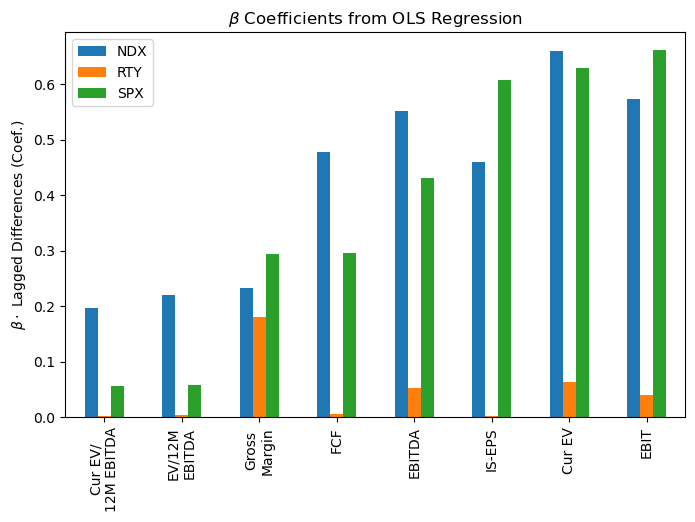

In [12]:
_, axes = plt.subplots(figsize = (8,5))

(df_param_prep
    .replace(PLOT_RENAMER)
    .rename(columns = {"ticker": ""})
    .pivot(index = "param_name", columns = "", values = "param_val")
    .sort_values("SPX")
    .plot(
        ax     = axes,
        kind   = "bar",
        xlabel = "",
        ylabel = r"$\beta \cdot$ Lagged Differences (Coef.)",
        title  = r"$\beta$ Coefficients from OLS Regression"))

plt.show()

# 2. Examining Factor Exposure

In [13]:
path          = os.path.join(data_path, "EquityForecastTickerGuide.xlsx")
df_ticker_map = (pd
    .read_excel(io = path, sheet_name = "FactorGuide")
    .loc[lambda x: x.est_field != "BEST_PE_RATIO"])

est_fields    = df_ticker_map.est_field.drop_duplicates().sort_values().to_list()

In [14]:
path   = os.path.join(daily_path, "DailyEstimateEquityIndexData.parquet")
df_est = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .loc[lambda x: x.ticker.isin(sample_tickers)]
    .loc[lambda x: x.field.isin(est_fields)])

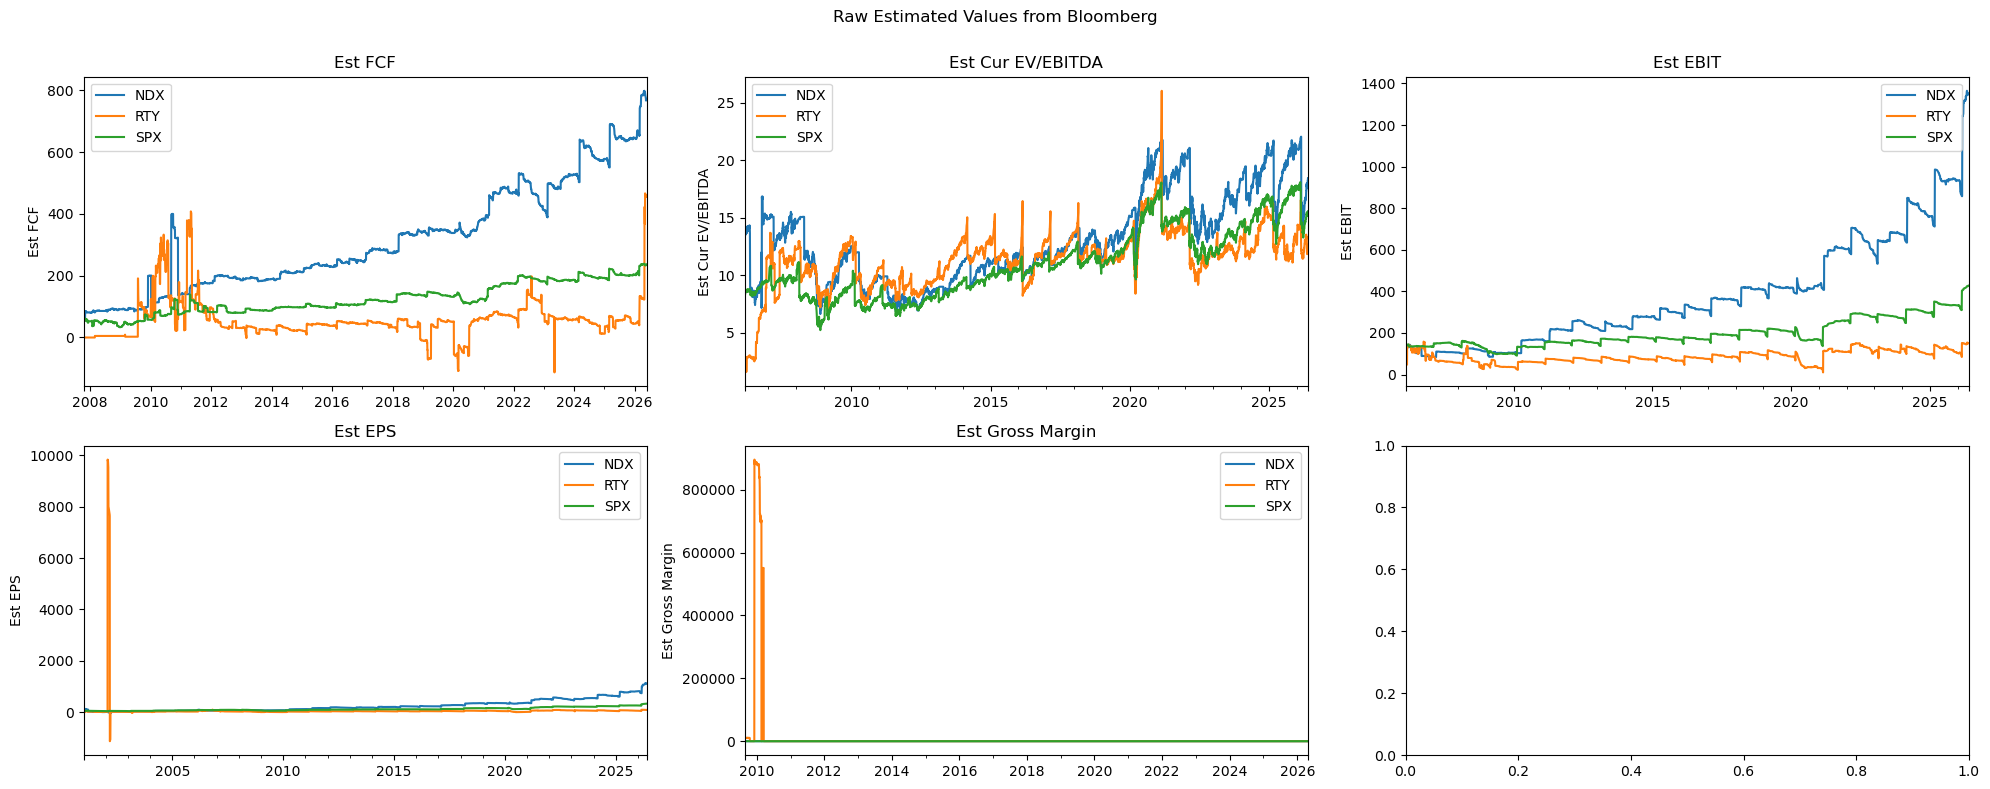

In [15]:
fields    = df_est.field.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = 3, nrows = 2, figsize = (20,8))

for field, ax in zip(fields, axes.flatten()): 

    df_tmp = (df_est
        .loc[lambda x: x.field == field]
        .assign(ticker = lambda x: x.ticker.str.split(" ").str[0])
        .drop(columns = ["field"])
        .drop_duplicates()
        .groupby(["date", "ticker"])
        .agg("min")
        .reset_index())

    (df_tmp
        .rename(columns = {"ticker": ""})
        .pivot(index = "date", columns = "", values = "value")
        .dropna()
        .plot(
            ax     = ax,
            ylabel = RENAMER[field],
            title  = RENAMER[field],
            xlabel = ""))

fig.suptitle("Raw Estimated Values from Bloomberg\n")
plt.tight_layout()

In [16]:
all_fields  = df_est.field.drop_duplicates().sort_values().to_list()
bad_fields  = ["BEST_EPS", "BEST_GROSS_MARGIN"]
good_fields = list(set(all_fields) - set(bad_fields))

In [17]:
df_tmp_good = (df_est
    .loc[lambda x: x.field.isin(good_fields)])

In [18]:
df_tmp_bad = (df_est
    .loc[lambda x: x.field.isin(bad_fields)]
    .assign(value = lambda x: np.where(np.abs(x.value) > 1_000, np.nan, x.value)))

df_cleaned = pd.concat([df_tmp_good, df_tmp_bad])

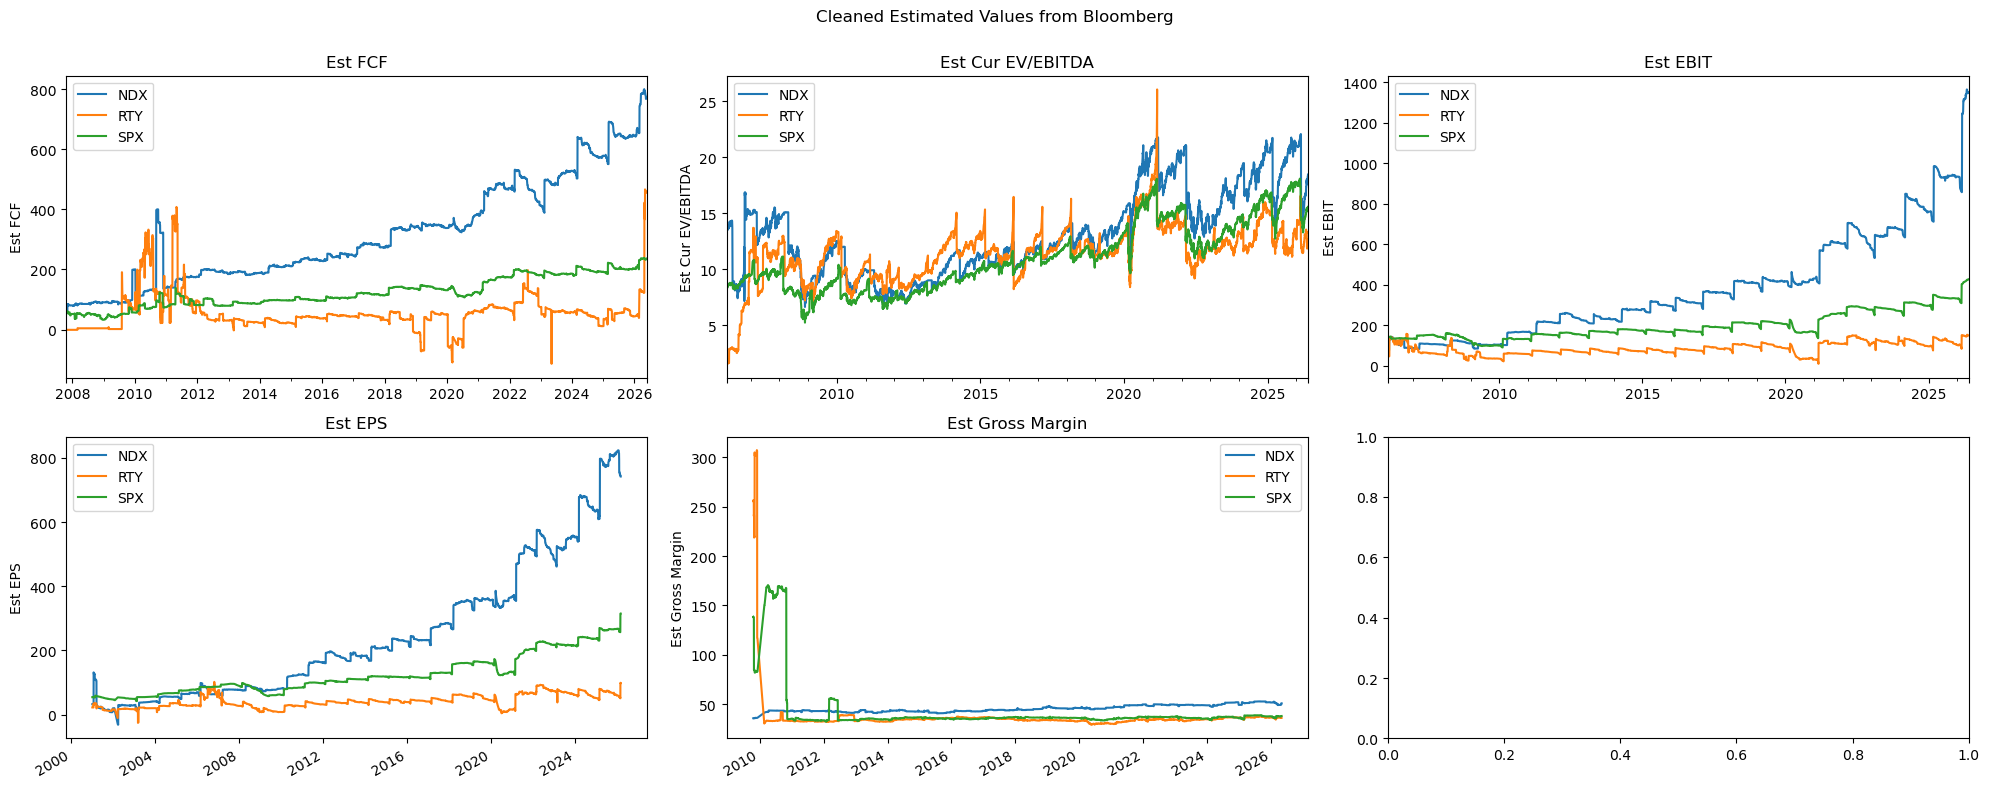

In [19]:
fields    = df_cleaned.field.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = 3, nrows = 2, figsize = (20,8))

for field, ax in zip(fields, axes.flatten()): 

    df_tmp = (df_cleaned
        .loc[lambda x: x.field == field]
        .assign(ticker = lambda x: x.ticker.str.split(" ").str[0])
        .drop(columns = ["field"])
        .drop_duplicates()
        .groupby(["date", "ticker"])
        .agg("min")
        .reset_index())

    (df_tmp
        .rename(columns = {"ticker": ""})
        .pivot(index = "date", columns = "", values = "value")
        .dropna()
        .plot(
            ax     = ax,
            ylabel = RENAMER[field],
            title  = RENAMER[field],
            xlabel = ""))

fig.suptitle("Cleaned Estimated Values from Bloomberg\n")
plt.tight_layout()

In [20]:
def _adj_data(df: pd.DataFrame, window: int = 10) -> pd.DataFrame:

    df_out = (df
        .groupby(["date", "field"])
        .agg("min")
        .reset_index()
        .pivot(index = "date", columns = "field", values = "value")
        .diff()
        .apply(lambda x: x / x.ewm(span = 10, adjust = False).std())
        .reset_index()
        .melt(id_vars = "date")
        .dropna())

    return df_out

df_est_adj = (df_est
    .groupby("ticker")
    .apply(_adj_data)
    .reset_index()
    .drop(columns = ["level_1"]))

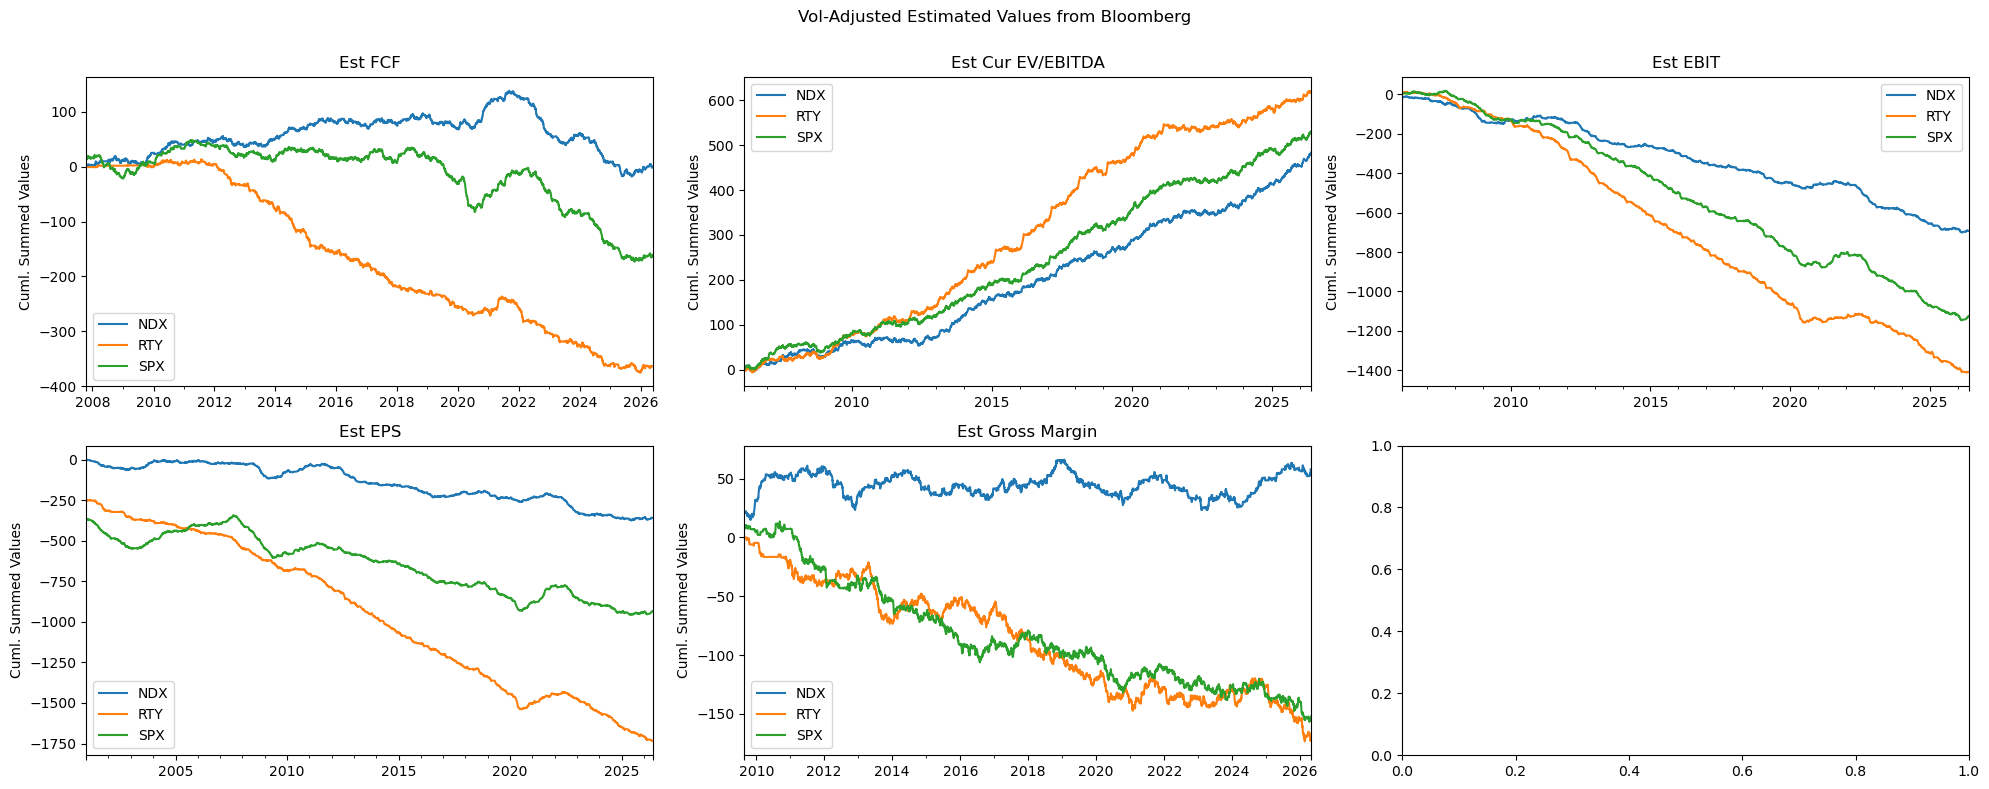

In [21]:
fields    = df_est_adj.field.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = 3, nrows = 2, figsize = (20,8))

for field, ax in zip(fields, axes.flatten()): 

    df_tmp = (df_est_adj
        .loc[lambda x: x.field == field]
        .assign(ticker = lambda x: x.ticker.str.split(" ").str[0])
        .drop(columns = ["field"])
        .drop_duplicates()
        .groupby(["date", "ticker"])
        .agg("min")
        .reset_index())

    (df_tmp
        .rename(columns = {"ticker": ""})
        .pivot(index = "date", columns = "", values = "value")
        .cumsum()
        .dropna()
        .plot(
            ax     = ax,
            ylabel = "Cuml. Summed Values",
            title  = RENAMER[field],
            xlabel = ""))

fig.suptitle("Vol-Adjusted Estimated Values from Bloomberg\n")
plt.tight_layout()

In [22]:
path       = os.path.join(daily_path, "DailyReturnsEquityIndexData.parquet")
df_raw_rtn = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .loc[lambda x: x.ticker.isin(sample_tickers)]
    .loc[lambda x: x.field == "DAY_TO_DAY_TOT_RETURN_GROSS_DVDS"]
    .drop(columns = ["field"])
    .assign(value = lambda x: x.value / 100))

In [23]:
def _get_vol_rtn(df: pd.DataFrame, target: float = 0.1, window: int = 100) -> pd.DataFrame: 

    df_out = (df
        .sort_values("date")
        .assign(
            vol         = lambda x: x.value.ewm(span = window, adjust = False).std(),
            vol_rtn     = lambda x: x.value * (target / (x.vol * np.sqrt(252))),
            lag_vol_rtn = lambda x: x.value * (target / (x.vol.shift() * np.sqrt(252))))
        .drop(columns = ["vol"])
        .set_index("date"))

    return df_out

target = 0.1
window = 100

df_vol_rtn = (df_raw_rtn
    .groupby("ticker")
    .apply(_get_vol_rtn, target, window)
    .reset_index()
    .dropna()
    .rename(columns = {"value": "rtn"}))

In [24]:
def _get_diff(df: pd.DataFrame) -> pd.DataFrame: 

    df_out = (df
        .dropna()
        .groupby(["date", "field"])
        .agg("min")
        .reset_index()
        .pivot(index = "date", columns = "field", values = "value")
        .diff()
        .reset_index()
        .melt(id_vars = "date", value_name = "raw_val")
        .dropna())

    return df_out

df_cleaned_diff = (df_cleaned
    .groupby("ticker")
    .apply(_get_diff)
    .reset_index()
    .drop(columns = ["level_1"]))

In [25]:
df_combined = (df_vol_rtn
    .melt(
        id_vars    = ["ticker", "date"], 
        var_name   = "vol_target",
        value_name = "rtn_val")
    .merge(
        right = df_est_adj, 
        how   = "inner",
        on    = ["date", "ticker"])
    .rename(columns = {"value": "est_val"})
    .merge(
        right = df_cleaned_diff, 
        how   = "inner",
        on    = ["date", "ticker", "field"])
    .melt(
        id_vars    = ["ticker", "date", "vol_target", "rtn_val", "field"],
        var_name   = "field_type",
        value_name = "fund_val")
    .assign(group_var = lambda x: x.ticker + "-" + x.vol_target + "-" + x.field + "-" + x.field_type))

In [51]:
path = os.path.join(base_path, "EstimatedFactorExposure.pkl")
with open(path, "rb") as f: models = pickle.load(f)

In [52]:
df_params = OLSModels().get_model_params(models)

In [53]:
df_param_prep = (df_params
    .loc[lambda x: x.param_name != "const"]
    .assign(
        ticker     = lambda x: x.name.str.split("-").str[0].str.split(" ").str[0],
        vol_target = lambda x: x.name.str.split("-").str[1],
        fund_var   = lambda x: x.name.str.split("-").str[2],
        val_type   = lambda x: x.name.str.split("-").str[3]))

In [54]:
(df_param_prep
    .replace(RENAMER)
    .rename(columns = {
        "vol_target": "Hedging",
        "fund_var"  : "Field",
        "val_type"  : "",
        "ticker"    : "Ticker"})
    .replace({
        "adj_val"  : "Adj.",
        "val"      : "Raw"})
    .pivot(index = ["Ticker", "Field"], columns = ["Hedging",""], values = "r2")
    .apply(lambda x: np.round(x,3)))

Hedging                  Lagged            No        Contemporaneous       
                           Adj.    Raw   Adj.    Raw            Adj.    Raw
Ticker Field                                                               
NDX    Est Cur EV/EBITDA  0.471  0.167  0.401  0.185           0.484  0.167
       Est EBIT           0.000  0.000  0.000  0.000           0.000  0.000
       Est EPS            0.001  0.000  0.001  0.000           0.001  0.000
       Est FCF            0.000  0.000  0.000  0.000           0.000  0.000
       Est Gross Margin   0.002  0.000  0.001  0.000           0.002  0.000
RTY    Est Cur EV/EBITDA  0.448  0.082  0.384  0.090           0.458  0.082
       Est EBIT           0.001  0.000  0.000  0.000           0.001  0.000
       Est EPS            0.001  0.000  0.001  0.000           0.001  0.000
       Est FCF            0.000  0.000  0.000  0.000           0.000  0.000
       Est Gross Margin   0.019  0.000  0.012  0.000           0.020  0.000
SPX    Est Cur EV/EBITDA  0.571  0.259  0.455  0.304           0.590  0.258
       Est EBIT           0.000  0.000  0.000  0.000           0.000  0.000
       Est EPS            0.004  0.000  0.005  0.000           0.004  0.000
       Est FCF            0.000  0.001  0.000  0.000           0.000  0.001
       Est Gross Margin   0.001  0.001  0.003  0.001           0.001  0.001

The $R^2$ aren't great but they give a baseline to compare our models too. 

In [59]:
display(df_param_prep
    .drop(columns = ["name", "param_name", "r2"])
    .melt(id_vars = ["vol_target", "fund_var", "val_type", "ticker"])
    .replace(RENAMER)
    .replace({
        "adj_val"  : "Adj.",
        "val"      : "Raw",
        "param_val": "Coef Value",
        "pvalue"   : r"$p$-value",
        "tvalue"   : r"$t$-value"})
    .rename(columns = {
        "fund_var"  : "Field",
        "val_type"  : "Est. Var",
        "variable"  : "",
        "vol_target": "Vol. Target",
        "ticker"    : "Ticker"})
    .pivot(index = ["Ticker", "Field", "Est. Var"], columns = ["", "Vol. Target"], values = "value")
    .apply(lambda x: np.round(x,3)))

Coef Value                        $p$-value  \
Vol. Target                           Lagged     No Contemporaneous    Lagged   
Ticker Field             Est. Var                                               
NDX    Est Cur EV/EBITDA Adj.          0.005  0.010           0.005     0.000   
                         Raw           0.009  0.020           0.008     0.000   
       Est EBIT          Adj.          0.000  0.000           0.000     0.830   
                         Raw          -0.000 -0.000          -0.000     0.426   
       Est EPS           Adj.          0.000  0.001           0.000     0.056   
                         Raw          -0.000 -0.000          -0.000     0.322   
       Est FCF           Adj.          0.000  0.000           0.000     0.426   
                         Raw           0.000  0.000           0.000     0.551   
       Est Gross Margin  Adj.         -0.000 -0.001          -0.000     0.009   
                         Raw          -0.001 -0.001          -0.001     0.336   
RTY    Est Cur EV/EBITDA Adj.          0.005  0.011           0.005     0.000   
                         Raw           0.005  0.014           0.005     0.000   
       Est EBIT          Adj.         -0.000 -0.000          -0.000     0.041   
                         Raw          -0.000 -0.000          -0.000     0.450   
       Est EPS           Adj.          0.000  0.001           0.000     0.001   
                         Raw          -0.000 -0.000          -0.000     0.869   
       Est FCF           Adj.         -0.000 -0.000          -0.000     0.320   
                         Raw           0.000  0.000           0.000     0.563   
       Est Gross Margin  Adj.         -0.001 -0.002          -0.001     0.000   
                         Raw           0.000  0.000           0.000     0.340   
SPX    Est Cur EV/EBITDA Adj.          0.005  0.009           0.005     0.000   
                         Raw           0.020  0.042           0.019     0.000   
       Est EBIT          Adj.          0.000  0.000           0.000     0.665   
                         Raw           0.000  0.000           0.000     0.638   
       Est EPS           Adj.          0.000  0.001           0.000     0.000   
                         Raw           0.000  0.000           0.000     0.363   
       Est FCF           Adj.          0.000  0.000           0.000     0.741   
                         Raw           0.000  0.000           0.000     0.040   
       Est Gross Margin  Adj.          0.000  0.001           0.000     0.028   
                         Raw           0.000  0.000           0.000     0.111   

                                                         $t$-value          \
Vol. Target                           No Contemporaneous    Lagged      No   
Ticker Field             Est. Var                                            
NDX    Est Cur EV/EBITDA Adj.      0.000           0.000    67.748  58.740   
                         Raw       0.000           0.000    32.092  34.235   
       Est EBIT          Adj.      0.599           0.848     0.215   0.525   
                         Raw       0.477           0.420    -0.797  -0.711   
       Est EPS           Adj.      0.006           0.058     1.908   2.732   
                         Raw       0.352           0.316    -0.991  -0.931   
       Est FCF           Adj.      0.862           0.361     0.797   0.174   
                         Raw       0.649           0.528     0.596   0.456   
       Est Gross Margin  Adj.      0.021           0.010    -2.601  -2.311   
                         Raw       0.239           0.322    -0.962  -1.177   
RTY    Est Cur EV/EBITDA Adj.      0.000           0.000    64.307  56.352   
                         Raw       0.000           0.000    21.358  22.401   
       Est EBIT          Adj.      0.189           0.039    -2.039  -1.313   
                         Raw       0.764           0.444    -0.755  -0.301   
       Est EPS           Adj.     

It's clear that the adjustment for the estimated value makes a huge improvement on the statistical-significance of the model 

In [64]:
display(df_param_prep
    .replace(RENAMER)
    .replace({
        "adj_val": "Adj",
        "val"    : "Raw"})
    .rename(columns = {
        "fund_var"  : "Field",
        "vol_target": "Vol. Target",
        "val_type"  : "",
        "ticker"    : "Ticker"})
    .pivot(index = ["Ticker", "Field"], columns = ["Vol. Target", ""], values = "tvalue")
    .apply(lambda x: np.round(x,3)))

Vol. Target               Lagged              No         Contemporaneous  \
                             Adj     Raw     Adj     Raw             Adj   
Ticker Field                                                               
NDX    Est Cur EV/EBITDA  67.748  32.092  58.740  34.235          69.484   
       Est EBIT            0.215  -0.797   0.525  -0.711           0.192   
       Est EPS             1.908  -0.991   2.732  -0.931           1.892   
       Est FCF             0.797   0.596   0.174   0.456           0.914   
       Est Gross Margin   -2.601  -0.962  -2.311  -1.177          -2.593   
RTY    Est Cur EV/EBITDA  64.307  21.358  56.352  22.401          65.555   
       Est EBIT           -2.039  -0.755  -1.313  -0.301          -2.060   
       Est EPS             3.317  -0.164   3.411  -0.143           3.253   
       Est FCF            -0.994   0.579  -1.047   0.353          -1.008   
       Est Gross Margin   -9.029   0.953  -6.991   0.840          -9.260   
SPX    Est Cur EV/EBITDA  82.437  42.254  65.236  47.252          85.790   
       Est EBIT            0.433   0.471   0.171   0.162           0.438   
       Est EPS             6.183   0.910   6.489   0.878           6.235   
       Est FCF             0.331   2.056   0.368   1.399           0.340   
       Est Gross Margin    2.194   1.596   3.711   1.923           2.120   

Vol. Target                       
                             Raw  
Ticker Field                      
NDX    Est Cur EV/EBITDA  32.189  
       Est EBIT           -0.807  
       Est EPS            -1.002  
       Est FCF             0.631  
       Est Gross Margin   -0.991  
RTY    Est Cur EV/EBITDA  21.367  
       Est EBIT           -0.765  
       Est EPS            -0.170  
       Est FCF             0.591  
       Est Gross Margin    0.970  
SPX    Est Cur EV/EBITDA  42.125  
       Est EBIT            0.568  
       Est EPS             1.003  
       Est FCF             2.091  
       Est Gross Margin    1.638